In [ ]:
# ---------- CELL 0: locate the project (same in every notebook) ----------
import os, sys
from pathlib import Path

def find_root(marker="PROJECT_ROOT.marker"):
    here = Path.cwd().resolve()                      # start where this notebook runs
    for folder in [here, *here.parents]:             # go UP one level at a time
        if (folder / marker).exists():
            return folder
    if "google.colab" in sys.modules:                # Colab: look inside Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        for pattern in (marker, f"*/{marker}", f"*/*/{marker}", f"*/*/*/{marker}"):
            hits = sorted(Path("/content/drive/MyDrive").glob(pattern))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("PROJECT_ROOT.marker not found - finish Day 1 first.")

ROOT = find_root()
os.chdir(ROOT / "notebooks")
RAW, CLEAN = ROOT/"data"/"raw", ROOT/"data"/"clean"
FEATURES, MODEL_OUT = ROOT/"data"/"features", ROOT/"data"/"model_outputs"
SQL_EXPORTS, BI_READY = ROOT/"data"/"sql_exports", ROOT/"data"/"bi_ready"
MODELS, REPORTS, DOCS = ROOT/"models", ROOT/"reports", ROOT/"docs"
FIGURES = REPORTS/"figures"
sys.path.append(str(ROOT/"src"))
print("Project root:", ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/Internmo/netflix_churn_project


In [ ]:
# ---------- CELL 1: load the clean tables ----------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
FIGURES.mkdir(parents=True, exist_ok=True)

AS_OF = pd.Timestamp((CLEAN / "as_of_date.txt").read_text().strip())

customers     = pd.read_csv(CLEAN / "customers.csv", parse_dates=["registration_date"])
plans         = pd.read_csv(CLEAN / "subscription_plans.csv")
subscriptions = pd.read_csv(CLEAN / "subscriptions.csv", parse_dates=["subscription_start_date", "subscription_end_date"])
content       = pd.read_csv(CLEAN / "content.csv")
viewing       = pd.read_csv(CLEAN / "viewing_activity.csv", parse_dates=["viewing_date"])
payments      = pd.read_csv(CLEAN / "payments.csv", parse_dates=["payment_date"])
tickets       = pd.read_csv(CLEAN / "support_tickets.csv", parse_dates=["ticket_date"])
feedback      = pd.read_csv(CLEAN / "customer_feedback.csv", parse_dates=["feedback_date"])
churn         = pd.read_csv(CLEAN / "churn_labels.csv", parse_dates=["churn_date"])
print("As-of date:", AS_OF.date())

As-of date: 2026-06-30


In [ ]:
# ---------- CELL 2: base table (one row per customer) ----------
current_plan = (subscriptions[subscriptions["subscription_end_date"].isna()]
                .merge(plans[["plan_id", "plan_name"]], on="plan_id")
                [["customer_id", "plan_name", "auto_renew", "subscription_status"]])

base = (customers.merge(churn[["customer_id", "churned", "churn_date", "churn_reason"]], on="customer_id")
                 .merge(current_plan, on="customer_id"))

base["tenure_years"] = (AS_OF - base["registration_date"]).dt.days / 365.25
base["age_band"] = pd.cut(base["age"], [0, 24, 34, 44, 54, 64, 120],
                          labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])
base["tenure_band"] = pd.cut(base["tenure_years"], [-0.01, 1, 2, 3, 5, 10],
                             labels=["under 1 yr", "1-2 yrs", "2-3 yrs", "3-5 yrs", "5+ yrs"])
base["churn_label"] = base["churned"].map({0: "Stayed", 1: "Churned"})

OVERALL_CHURN = 100 * base["churned"].mean()
print(len(base), "customers | overall churn rate:", round(OVERALL_CHURN, 1), "%")
base.head(3)

8000 customers | overall churn rate: 24.9 %


,customer_id,first_name,last_name,age,gender,country,state_or_region,city,registration_date,acquisition_channel,...,churned,churn_date,churn_reason,plan_name,auto_renew,subscription_status,tenure_years,age_band,tenure_band,churn_label
0,CUST000744,Riya,Santos,21,Female,United Kingdom,NaN,Liverpool,2019-06-03,Organic Search,...,0,NaT,NaN,Premium,0,Active,7.074606,18-24,5+ yrs,Stayed
1,CUST001502,Ananya,Hussain,31,Male,Canada,NaN,Montreal,2026-01-13,Referral,...,0,NaT,NaN,Basic,1,Active,0.459959,25-34,under 1 yr,Stayed
2,CUST005383,Zara,Banda,40,Male,United Kingdom,NaN,Leeds,2023-06-17,Paid Social,...,0,NaT,NaN,Basic,1,Active,3.036277,35-44,3-5 yrs,Stayed


In [ ]:
# ---------- CELL 3: helper functions ----------
summary_tables = []          # every churn-by-group table is collected here and saved at the end

def save_chart(name):
    """Save the current chart as reports/figures/<name>.png and show it."""
    plt.tight_layout()
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close()

def churn_by(df, column, number, title, top=None, horizontal=False):
    """Churn rate for each group of `column`, drawn as a bar chart, with the overall rate as a dashed line."""
    table = (df.groupby(column, observed=True)
               .agg(customers=("customer_id", "count"), churned=("churned", "sum"))
               .assign(churn_rate_pct=lambda t: (100 * t["churned"] / t["customers"]).round(1))
               .sort_values("churn_rate_pct", ascending=False))
    if top:
        table = table.head(top)
    fig, ax = plt.subplots(figsize=(8, 4.5) if not horizontal else (8, 5))
    if horizontal:
        ax.barh(table.index.astype(str), table["churn_rate_pct"], color="#b20710")
        ax.axvline(OVERALL_CHURN, color="black", linestyle="--", label=f"overall {OVERALL_CHURN:.1f}%")
        ax.invert_yaxis(); ax.set_xlabel("churn rate (%)")
    else:
        ax.bar(table.index.astype(str), table["churn_rate_pct"], color="#b20710")
        ax.axhline(OVERALL_CHURN, color="black", linestyle="--", label=f"overall {OVERALL_CHURN:.1f}%")
        ax.set_ylabel("churn rate (%)"); plt.xticks(rotation=30, ha="right")
    ax.set_title(title); ax.legend()
    save_chart(f"{number}_{column}_churn_rate")
    summary_tables.append(table.reset_index().rename(columns={column: "group"}).assign(category=column))
    return table

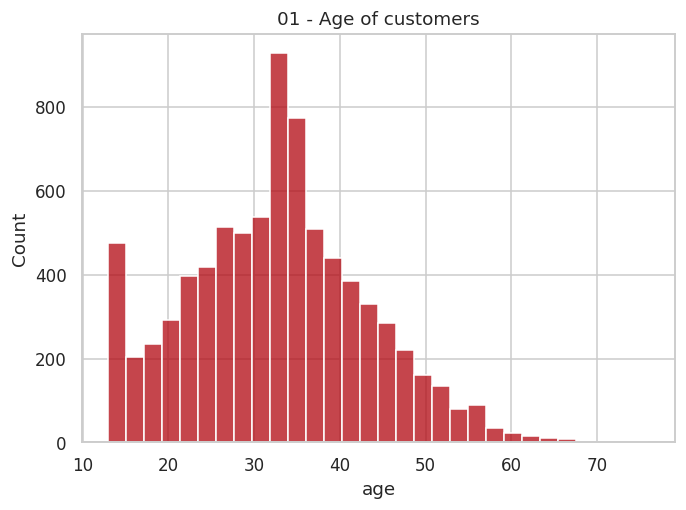

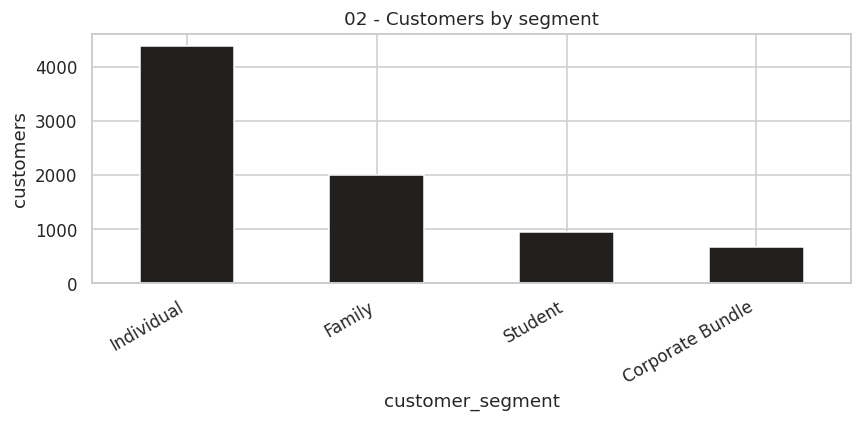

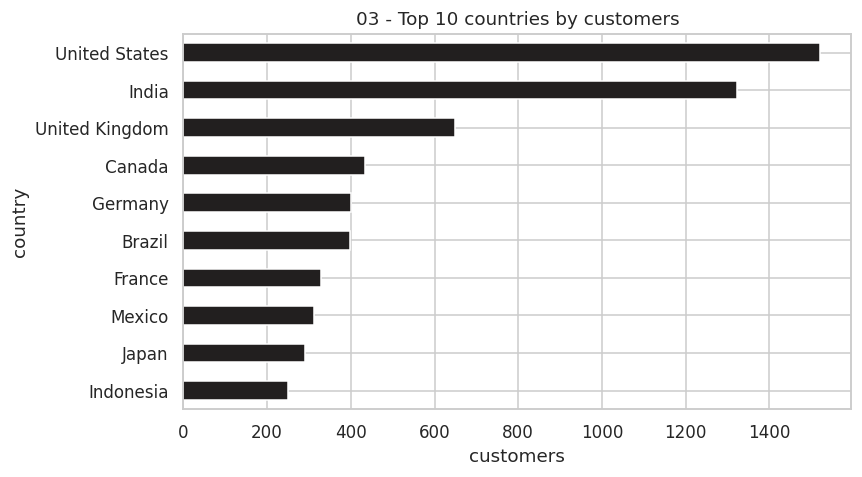

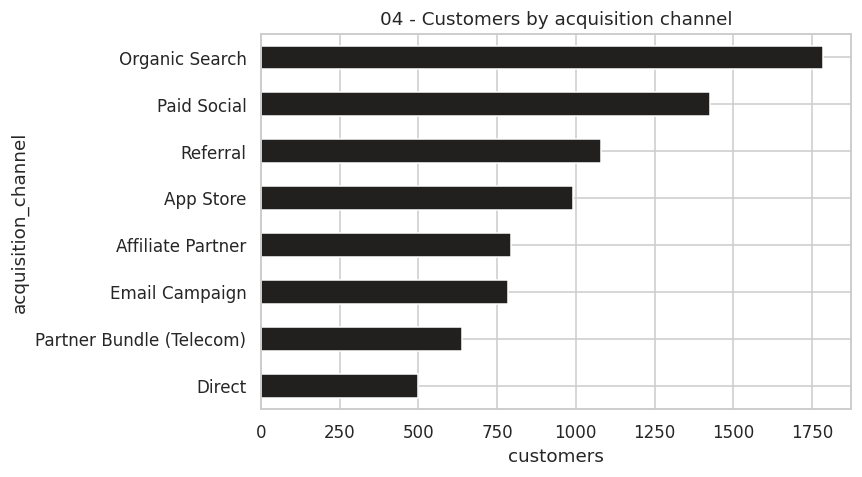

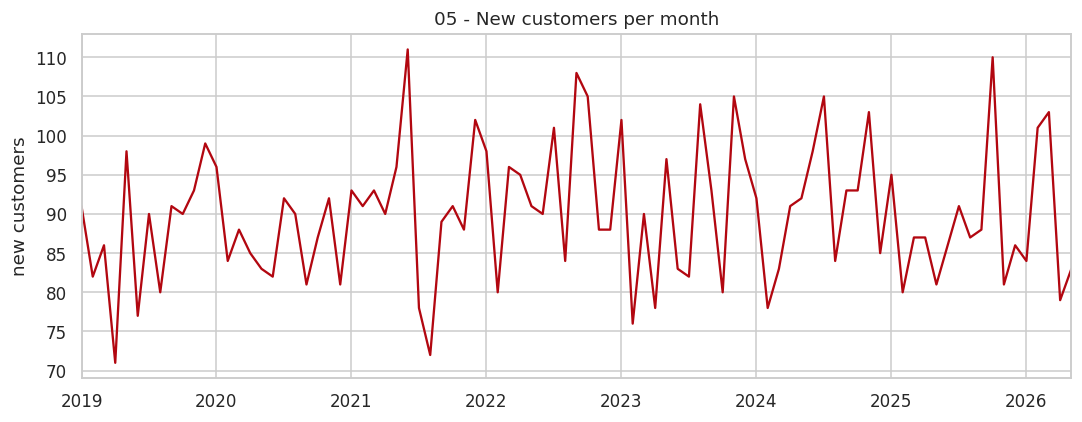

In [ ]:
# ---------- CELL 4: customer profile ----------
# 01 age distribution
sns.histplot(base["age"], bins=30, color="#b20710")
plt.title("01 - Age of customers"); plt.xlabel("age")
save_chart("01_age_distribution")

# 02 customers per segment
base["customer_segment"].value_counts().plot(kind="bar", color="#221f1f", figsize=(8, 4))
plt.title("02 - Customers by segment"); plt.ylabel("customers"); plt.xticks(rotation=30, ha="right")
save_chart("02_customers_by_segment")

# 03 top 10 countries
base["country"].value_counts().head(10).sort_values().plot(kind="barh", color="#221f1f", figsize=(8, 4.5))
plt.title("03 - Top 10 countries by customers"); plt.xlabel("customers")
save_chart("03_top10_countries")

# 04 acquisition channels
base["acquisition_channel"].value_counts().sort_values().plot(kind="barh", color="#221f1f", figsize=(8, 4.5))
plt.title("04 - Customers by acquisition channel"); plt.xlabel("customers")
save_chart("04_acquisition_channels")

# 05 new customers per month
signups = base.set_index("registration_date").resample("MS").size()
signups.plot(figsize=(10, 4), color="#b20710")
plt.title("05 - New customers per month"); plt.ylabel("new customers"); plt.xlabel("")
save_chart("05_signups_per_month")

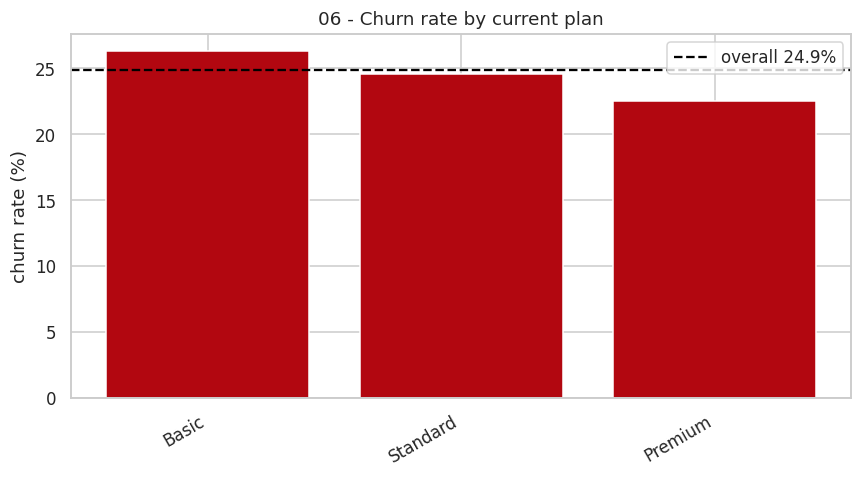

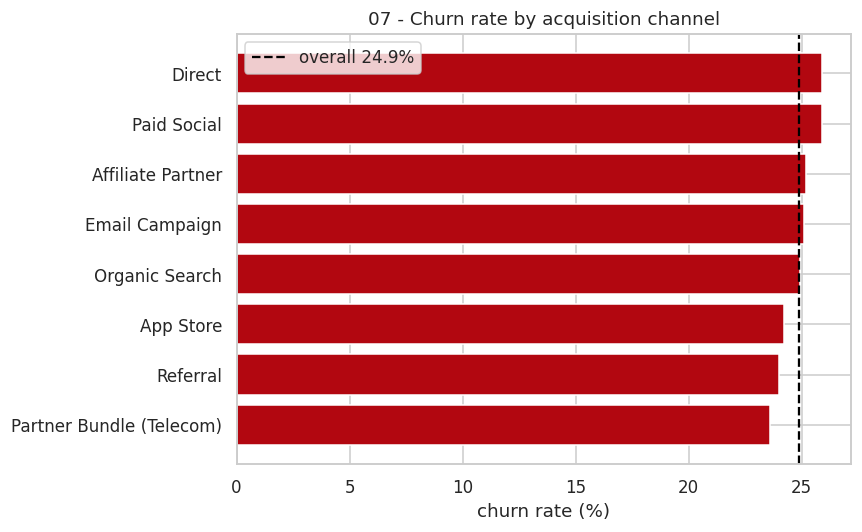

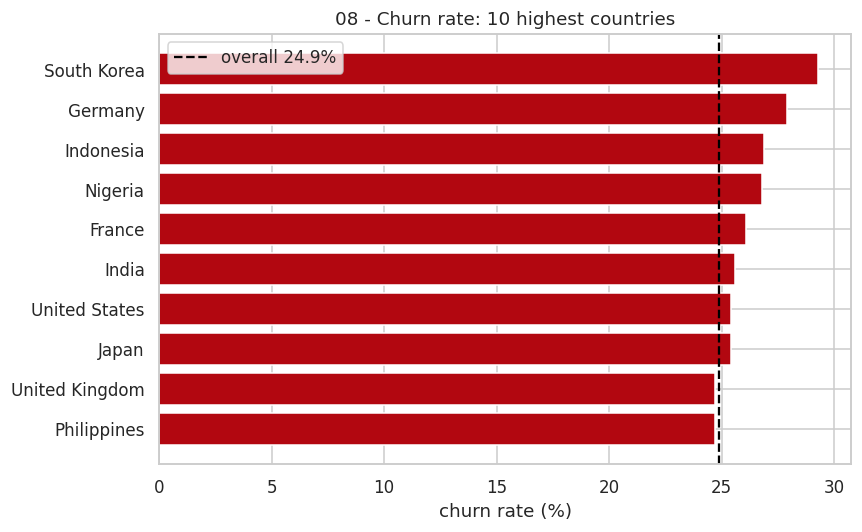

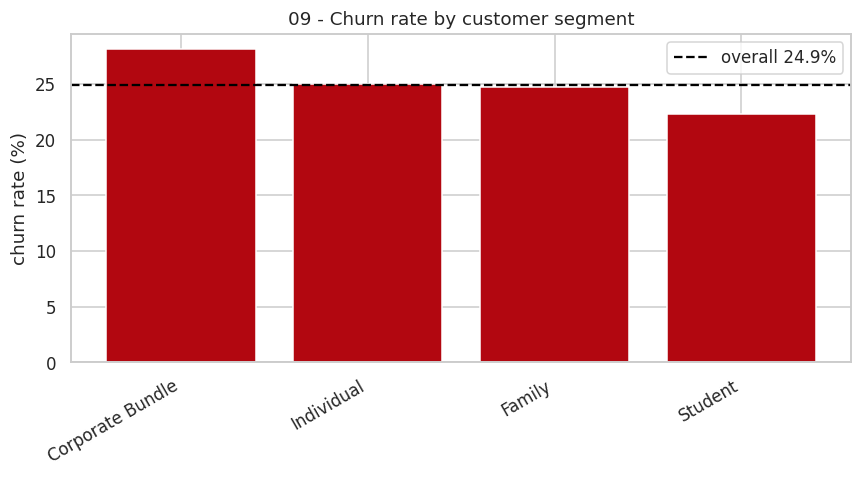

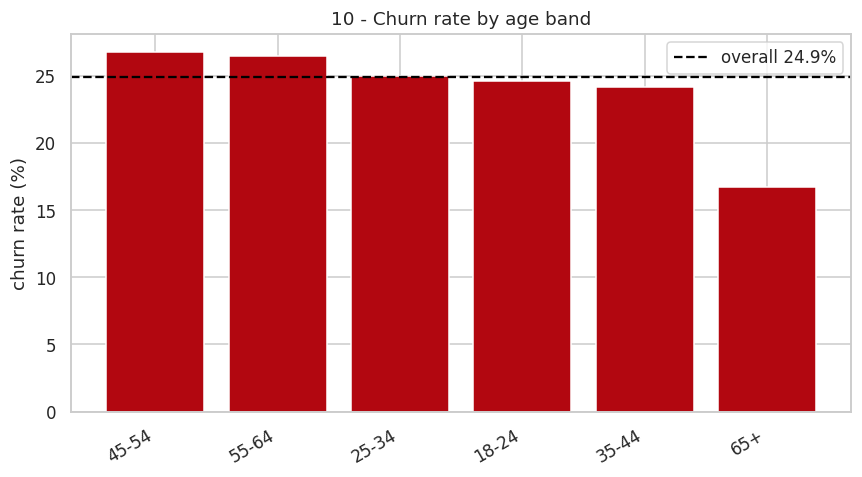

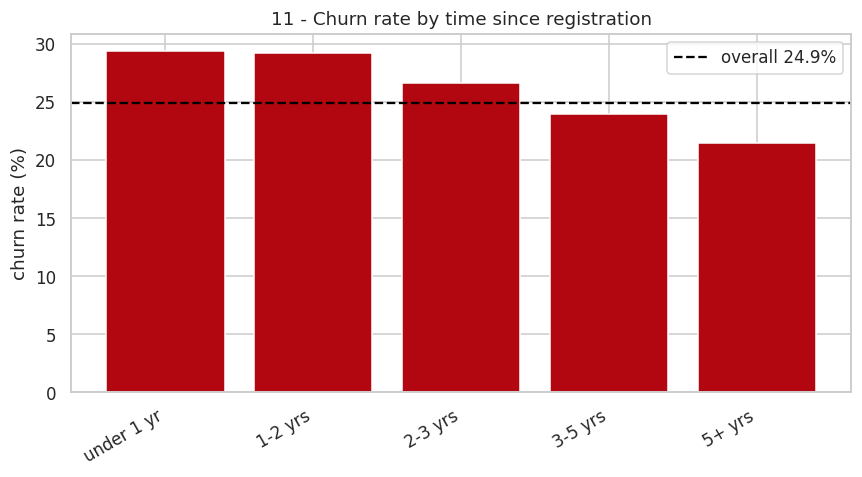

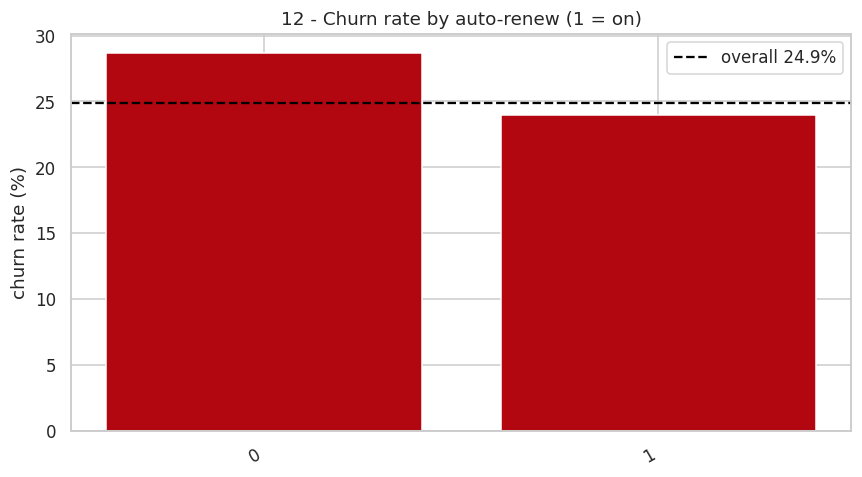

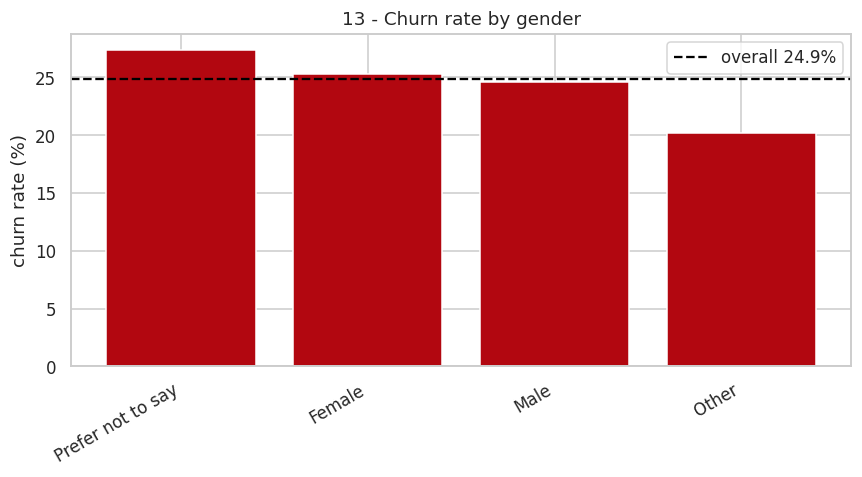

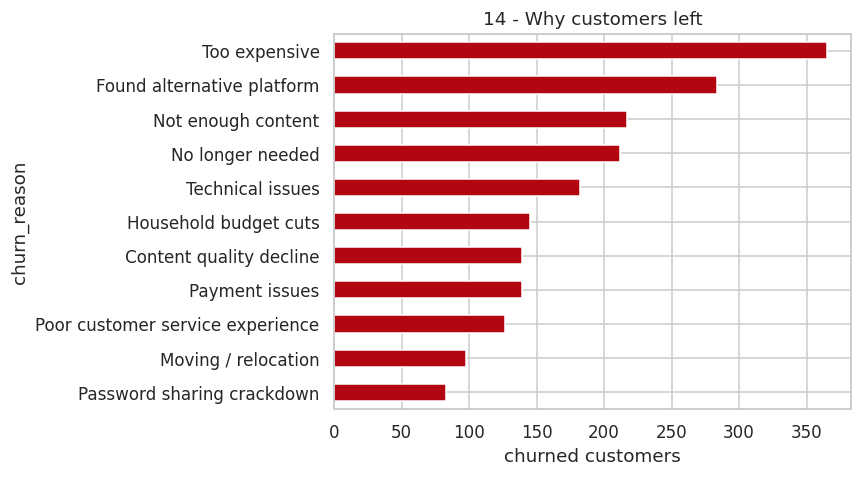

In [ ]:
# ---------- CELL 5: churn rate by customer and plan characteristics ----------
churn_by(base, "plan_name",           "06", "06 - Churn rate by current plan")
churn_by(base, "acquisition_channel", "07", "07 - Churn rate by acquisition channel", horizontal=True)
churn_by(base, "country",             "08", "08 - Churn rate: 10 highest countries", top=10, horizontal=True)
churn_by(base, "customer_segment",    "09", "09 - Churn rate by customer segment")
churn_by(base, "age_band",            "10", "10 - Churn rate by age band")
churn_by(base, "tenure_band",         "11", "11 - Churn rate by time since registration")
churn_by(base, "auto_renew",          "12", "12 - Churn rate by auto-renew (1 = on)")
churn_by(base, "gender",              "13", "13 - Churn rate by gender")

# 14 reasons given by churned customers
base.loc[base["churned"] == 1, "churn_reason"].value_counts().sort_values().plot(kind="barh", color="#b20710", figsize=(8, 4.5))
plt.title("14 - Why customers left"); plt.xlabel("churned customers")
save_chart("14_churn_reasons")

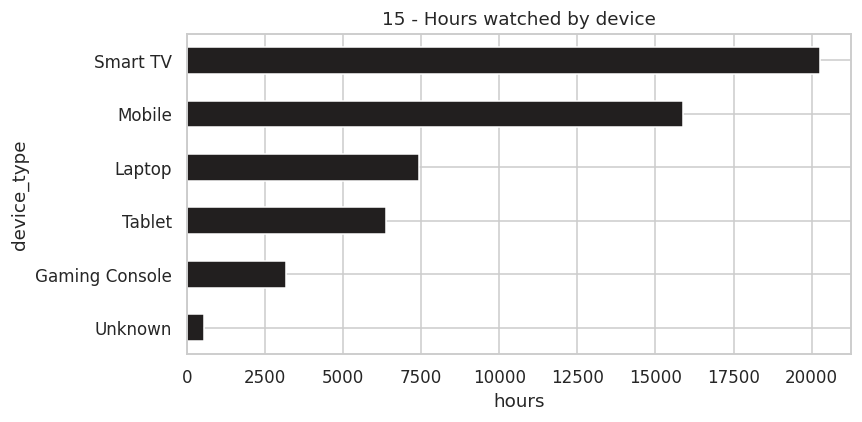

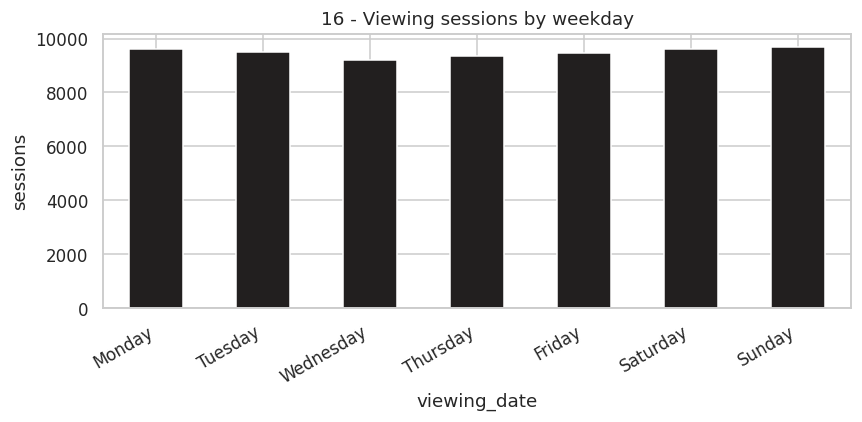

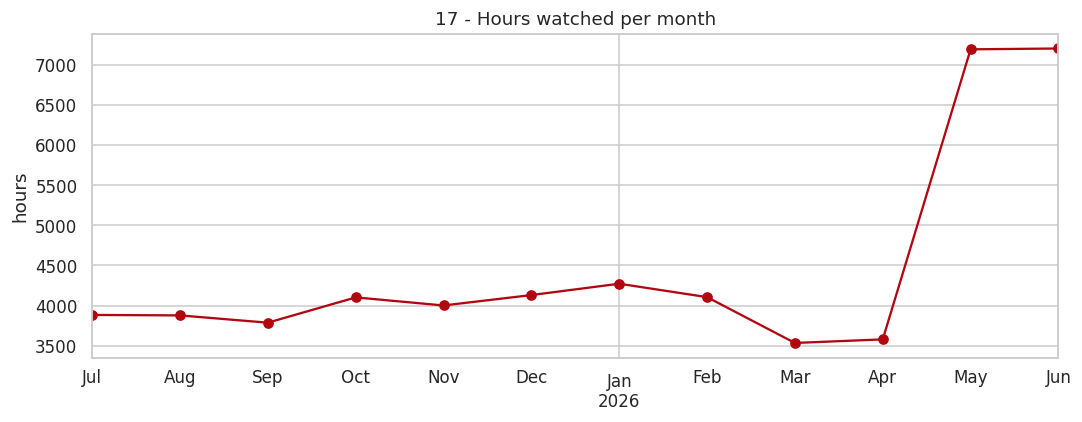

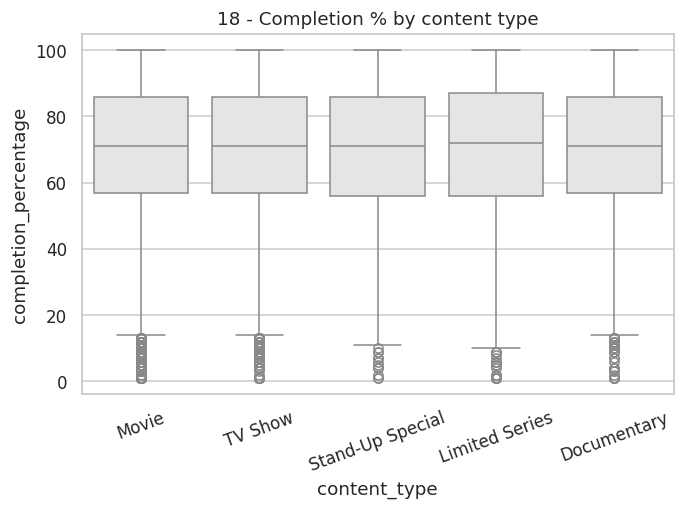

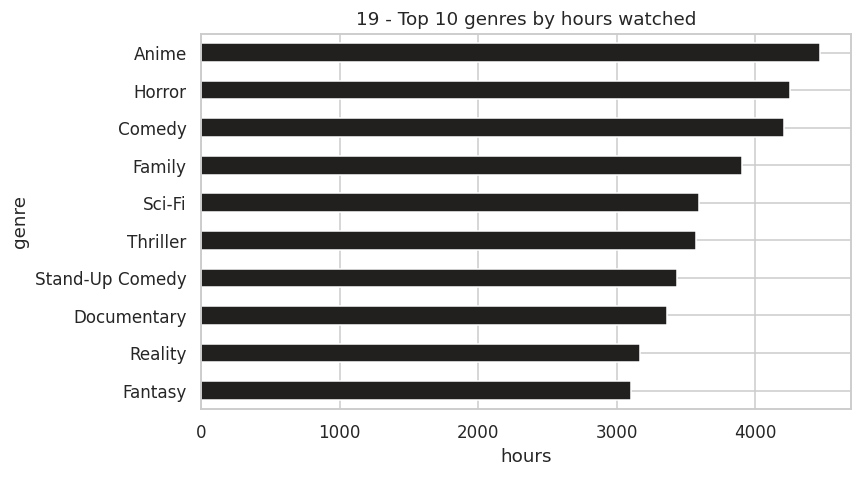

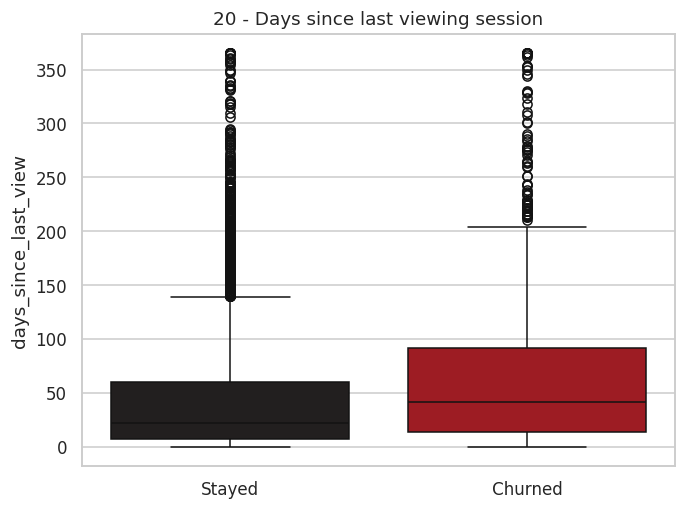

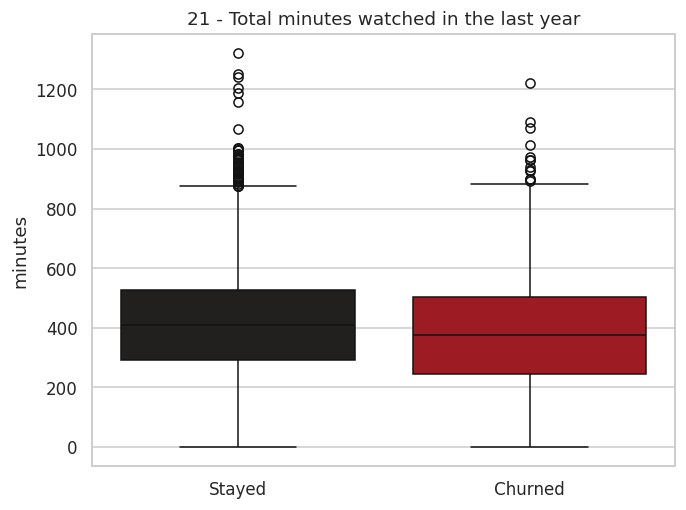

             sessions  minutes  days_since_last_view
churn_label                                         
Churned           8.0    375.0                  42.0
Stayed            9.0    409.0                  22.0


In [ ]:
# ---------- CELL 6: viewing behaviour ----------
views = viewing.merge(content[["content_id", "content_type", "genre"]], on="content_id")

# 15 minutes per device
(viewing.groupby("device_type")["watch_duration_minutes"].sum().div(60).sort_values()
 .plot(kind="barh", color="#221f1f", figsize=(8, 4)))
plt.title("15 - Hours watched by device"); plt.xlabel("hours")
save_chart("15_hours_by_device")

# 16 sessions per weekday
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
(viewing["viewing_date"].dt.day_name().value_counts().reindex(weekday_order)
 .plot(kind="bar", color="#221f1f", figsize=(8, 4)))
plt.title("16 - Viewing sessions by weekday"); plt.ylabel("sessions"); plt.xticks(rotation=30, ha="right")
save_chart("16_sessions_by_weekday")

# 17 monthly hours watched
monthly_hours = viewing.set_index("viewing_date")["watch_duration_minutes"].resample("MS").sum() / 60
monthly_hours.plot(figsize=(10, 4), marker="o", color="#b20710")
plt.title("17 - Hours watched per month"); plt.ylabel("hours"); plt.xlabel("")
save_chart("17_monthly_hours_watched")

# 18 completion by content type
sns.boxplot(data=views, x="content_type", y="completion_percentage", color="#e5e5e5")
plt.title("18 - Completion % by content type"); plt.xticks(rotation=20)
save_chart("18_completion_by_content_type")

# 19 most watched genres
(views.groupby("genre")["watch_duration_minutes"].sum().div(60).sort_values().tail(10)
 .plot(kind="barh", color="#221f1f", figsize=(8, 4.5)))
plt.title("19 - Top 10 genres by hours watched"); plt.xlabel("hours")
save_chart("19_top_genres")

# per-customer viewing summary (also reused on Day 9)
per_customer = (viewing.groupby("customer_id")
                .agg(sessions=("viewing_id", "count"),
                     minutes=("watch_duration_minutes", "sum"),
                     last_view=("viewing_date", "max"))
                .reset_index())
per_customer["days_since_last_view"] = (AS_OF - per_customer["last_view"]).dt.days
eng = base.merge(per_customer, on="customer_id", how="left")
eng["sessions"] = eng["sessions"].fillna(0)
eng["minutes"] = eng["minutes"].fillna(0)
eng["days_since_last_view"] = eng["days_since_last_view"].fillna(365)

# 20 days since last viewing: churned vs stayed
sns.boxplot(data=eng, x="churn_label", y="days_since_last_view", palette=["#221f1f", "#b20710"], order=["Stayed", "Churned"], hue="churn_label", legend=False)
plt.title("20 - Days since last viewing session"); plt.xlabel("")
save_chart("20_days_since_last_view")

# 21 total minutes watched: churned vs stayed
sns.boxplot(data=eng, x="churn_label", y="minutes", palette=["#221f1f", "#b20710"], order=["Stayed", "Churned"], hue="churn_label", legend=False)
plt.title("21 - Total minutes watched in the last year"); plt.xlabel("")
save_chart("21_minutes_watched_by_churn")

print(eng.groupby("churn_label")[["sessions", "minutes", "days_since_last_view"]].median())

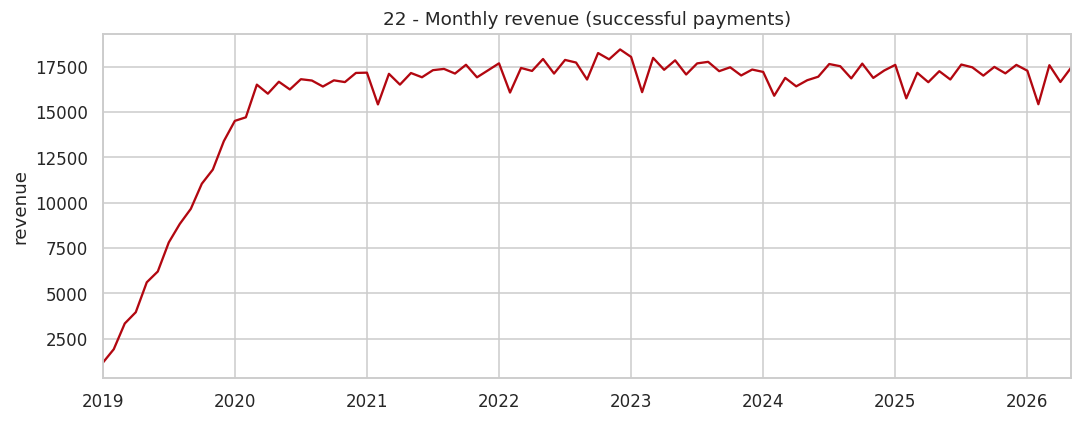

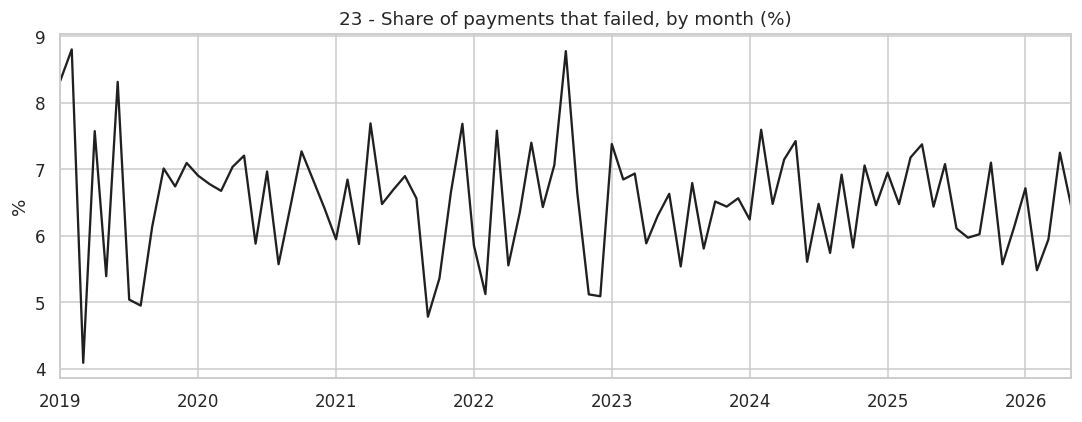

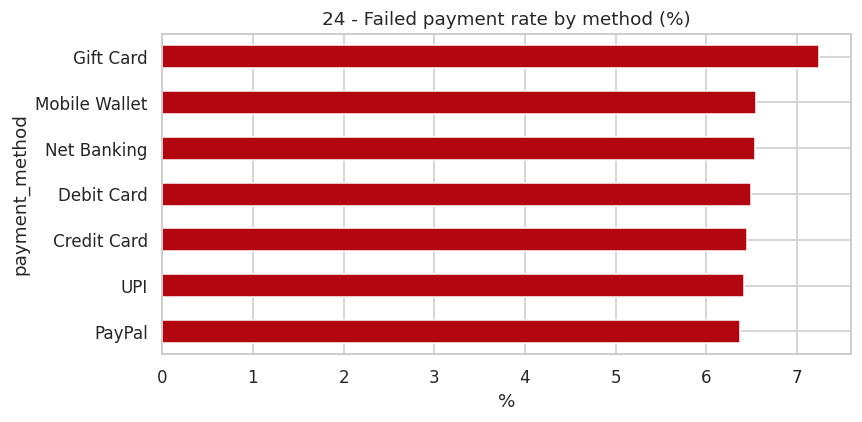

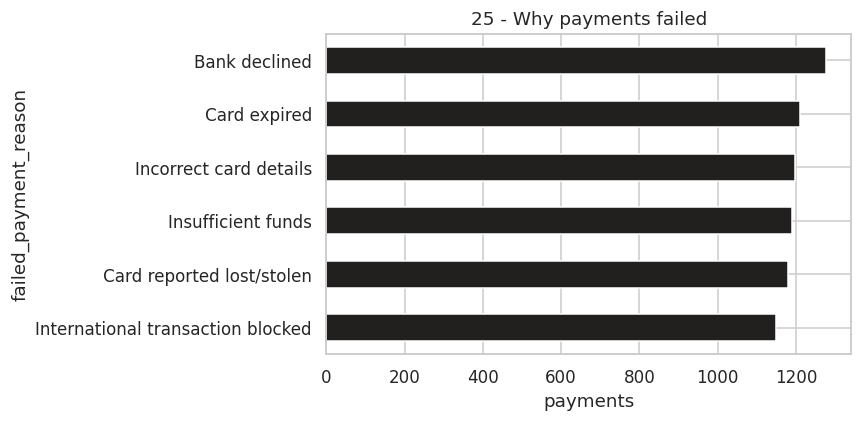

In [ ]:
# ---------- CELL 7: payments ----------
paid = payments[payments["payment_status"] == "Success"]

# 22 monthly revenue
paid.set_index("payment_date")["amount"].resample("MS").sum().plot(figsize=(10, 4), color="#b20710")
plt.title("22 - Monthly revenue (successful payments)"); plt.ylabel("revenue"); plt.xlabel("")
save_chart("22_monthly_revenue")

# 23 failed payment rate by month
failed_rate = payments.assign(failed=(payments["payment_status"] == "Failed")).set_index("payment_date")["failed"].resample("MS").mean() * 100
failed_rate.plot(figsize=(10, 4), color="#221f1f")
plt.title("23 - Share of payments that failed, by month (%)"); plt.ylabel("%"); plt.xlabel("")
save_chart("23_failed_payment_rate")

# 24 failed rate by payment method
(payments.assign(failed=(payments["payment_status"] == "Failed")).groupby("payment_method")["failed"].mean().mul(100).sort_values()
 .plot(kind="barh", color="#b20710", figsize=(8, 4)))
plt.title("24 - Failed payment rate by method (%)"); plt.xlabel("%")
save_chart("24_failed_by_method")

# 25 reasons for failed payments
payments["failed_payment_reason"].value_counts().sort_values().plot(kind="barh", color="#221f1f", figsize=(8, 4))
plt.title("25 - Why payments failed"); plt.xlabel("payments")
save_chart("25_failed_reasons")

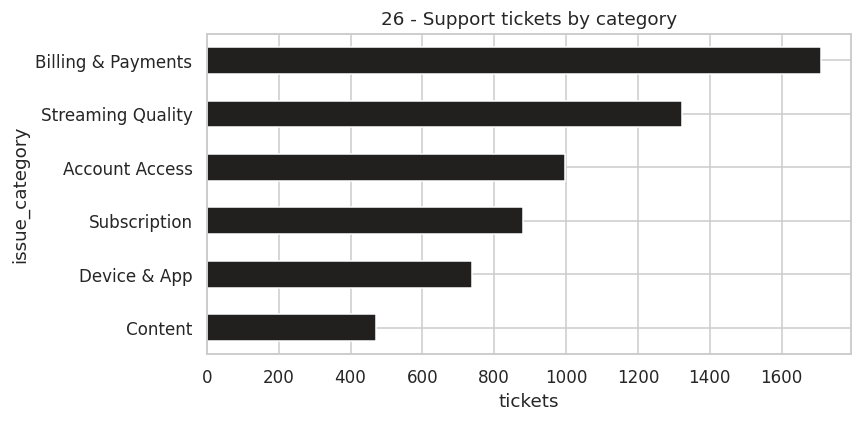

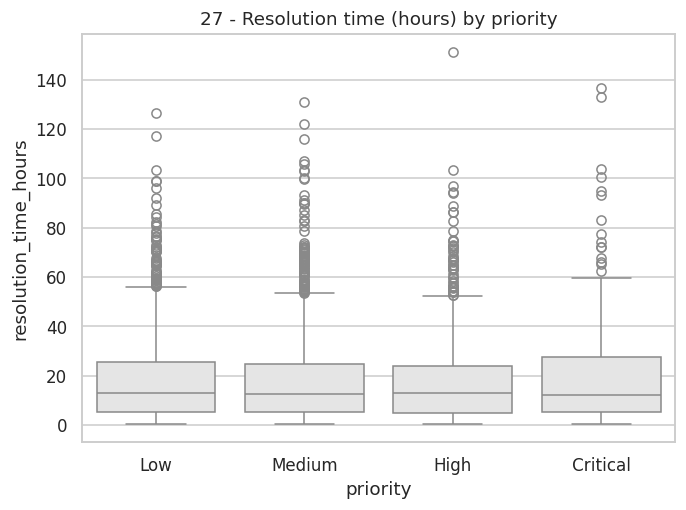

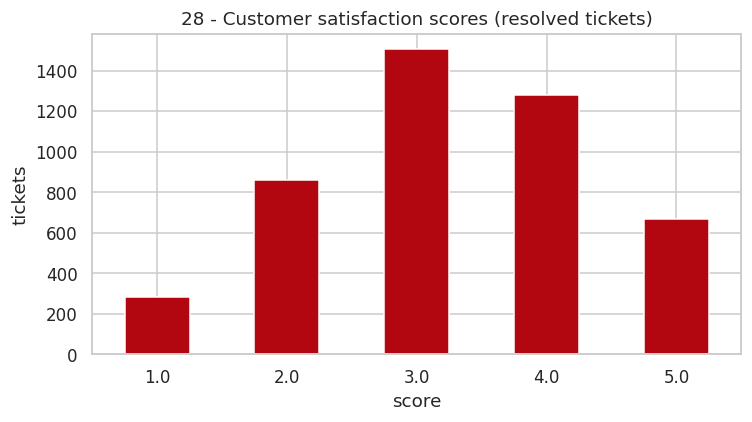

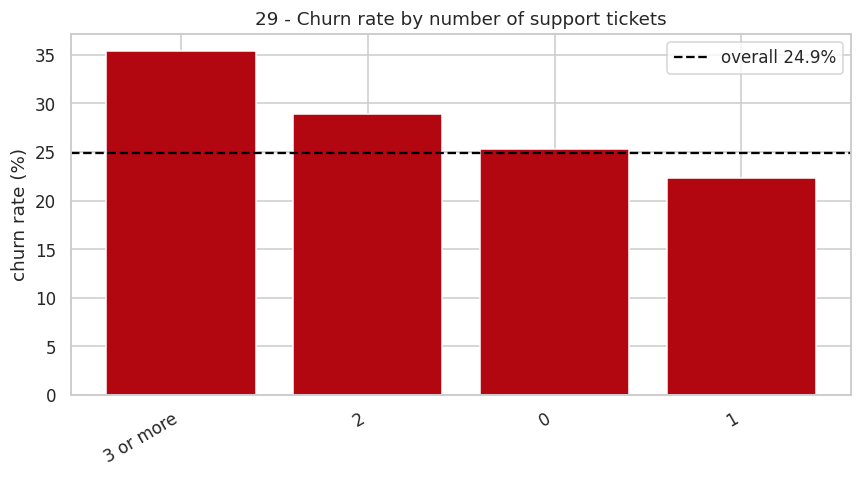

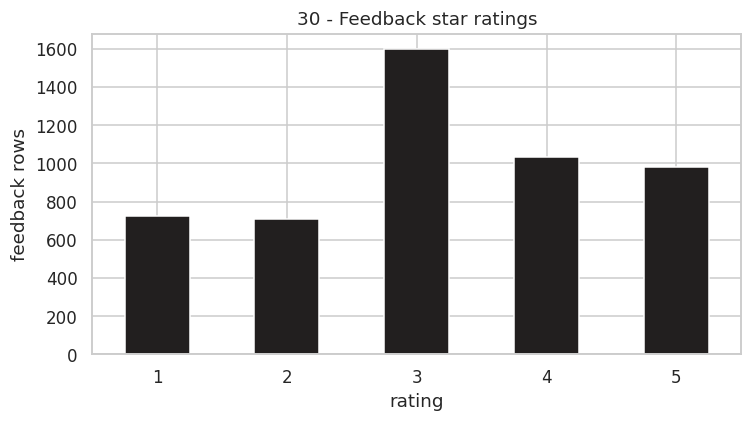

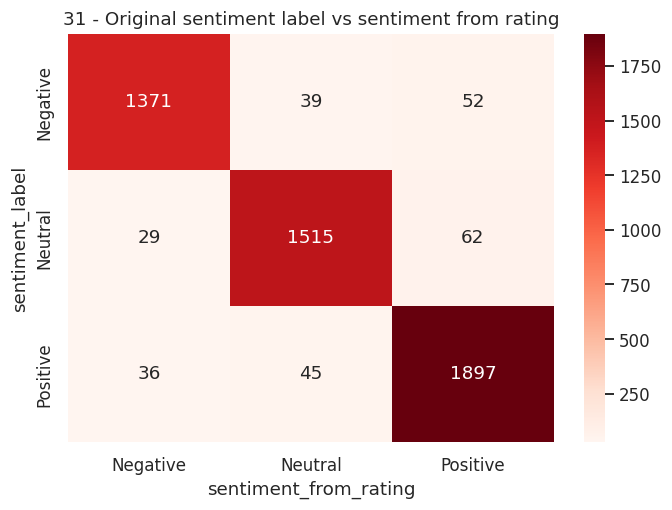

In [ ]:
# ---------- CELL 8: support tickets and feedback ----------
# 26 tickets by category
tickets["issue_category"].value_counts().sort_values().plot(kind="barh", color="#221f1f", figsize=(8, 4))
plt.title("26 - Support tickets by category"); plt.xlabel("tickets")
save_chart("26_tickets_by_category")

# 27 resolution time by priority
priority_order = ["Low", "Medium", "High", "Critical"]
sns.boxplot(data=tickets, x="priority", y="resolution_time_hours", order=[p for p in priority_order if p in tickets["priority"].unique()], color="#e5e5e5")
plt.title("27 - Resolution time (hours) by priority")
save_chart("27_resolution_by_priority")

# 28 satisfaction scores
tickets["customer_satisfaction_score"].value_counts().sort_index().plot(kind="bar", color="#b20710", figsize=(7, 4))
plt.title("28 - Customer satisfaction scores (resolved tickets)"); plt.xlabel("score"); plt.ylabel("tickets"); plt.xticks(rotation=0)
save_chart("28_csat_distribution")

# 29 churn rate by number of tickets
ticket_counts = tickets.groupby("customer_id").size().rename("ticket_count")
with_tickets = base.merge(ticket_counts, on="customer_id", how="left")
with_tickets["ticket_count"] = with_tickets["ticket_count"].fillna(0).astype(int)
with_tickets["tickets_group"] = pd.cut(with_tickets["ticket_count"], [-1, 0, 1, 2, 100], labels=["0", "1", "2", "3 or more"])
churn_by(with_tickets, "tickets_group", "29", "29 - Churn rate by number of support tickets")

# 30 rating distribution
feedback["rating"].value_counts().sort_index().plot(kind="bar", color="#221f1f", figsize=(7, 4))
plt.title("30 - Feedback star ratings"); plt.xlabel("rating"); plt.ylabel("feedback rows"); plt.xticks(rotation=0)
save_chart("30_rating_distribution")

# 31 label vs rating-based sentiment (shows the noisy label)
sns.heatmap(pd.crosstab(feedback["sentiment_label"], feedback["sentiment_from_rating"]), annot=True, fmt="d", cmap="Reds")
plt.title("31 - Original sentiment label vs sentiment from rating")
save_chart("31_label_vs_rating_sentiment")

In [10]:
# ---------- CELL 9: Python vs SQL ----------
sql_channel = pd.read_csv(SQL_EXPORTS / "q04_churn_by_channel.csv")          # exported on Day 5
py_channel = (base.groupby("acquisition_channel")
                  .agg(customers=("customer_id", "count"), churned=("churned", "sum"))
                  .reset_index())
check = sql_channel.merge(py_channel, on="acquisition_channel", suffixes=("_sql", "_python"))
assert (check["customers_sql"] == check["customers_python"]).all()
assert (check["churned_customers"] == check["churned"]).all()
print("OK: churn counts per channel are identical in SQL and Python")

OK: churn counts per channel are identical in SQL and Python


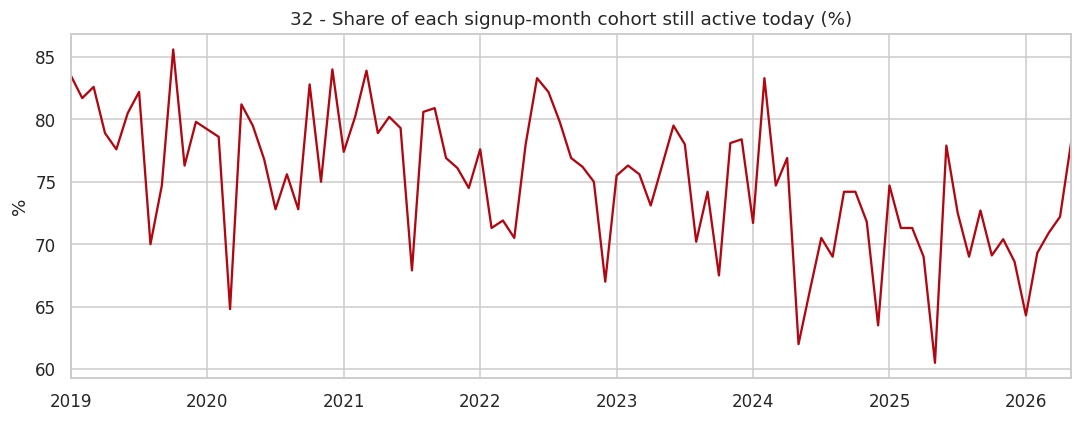

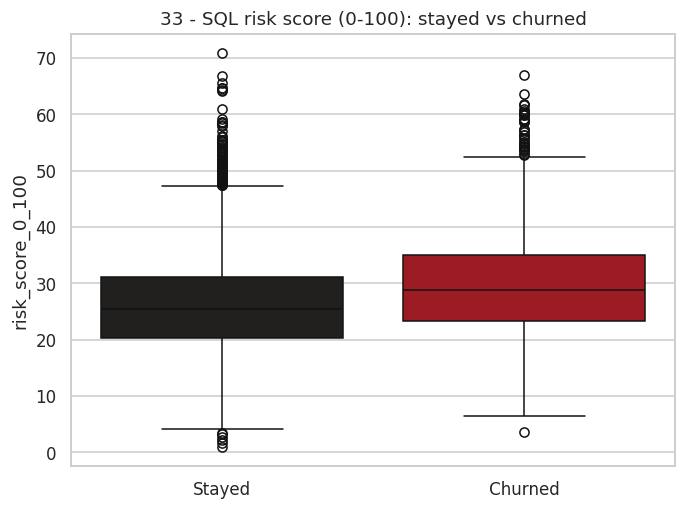

             mean   50%
churn_label            
Churned      29.7  28.9
Stayed       26.0  25.5


In [11]:
# ---------- CELL 10: use the SQL exports ----------
cohort = pd.read_csv(SQL_EXPORTS / "q20_cohort_retention.csv")
cohort["cohort_month"] = pd.to_datetime(cohort["cohort_month"])
cohort.set_index("cohort_month")["still_active_today_pct"].plot(figsize=(10, 4), color="#b20710")
plt.title("32 - Share of each signup-month cohort still active today (%)"); plt.ylabel("%"); plt.xlabel("")
save_chart("32_cohort_still_active")

health = pd.read_csv(SQL_EXPORTS / "q37_customer_health_score.csv")
health["churn_label"] = health["churned"].map({0: "Stayed", 1: "Churned"})
sns.boxplot(data=health, x="churn_label", y="risk_score_0_100", order=["Stayed", "Churned"],
            palette=["#221f1f", "#b20710"], hue="churn_label", legend=False)
plt.title("33 - SQL risk score (0-100): stayed vs churned"); plt.xlabel("")
save_chart("33_sql_risk_score_by_churn")
print(health.groupby("churn_label")["risk_score_0_100"].describe()[["mean", "50%"]].round(1))

In [12]:
# ---------- CELL 11: save the churn-by-group summary ----------
eda_summary = pd.concat(summary_tables, ignore_index=True)[["category", "group", "customers", "churned", "churn_rate_pct"]]
eda_summary["gap_vs_overall_pts"] = (eda_summary["churn_rate_pct"] - round(OVERALL_CHURN, 1)).round(1)
eda_summary.to_csv(REPORTS / "eda_churn_by_group.csv", index=False)

# the 10 groups that differ the most from the overall rate (only groups with at least 100 customers)
eligible = eda_summary[eda_summary["customers"] >= 100].copy()
eligible["abs_gap"] = eligible["gap_vs_overall_pts"].abs()
biggest_gaps = eligible.sort_values("abs_gap", ascending=False).head(10)
biggest_gaps

,category,group,customers,churned,churn_rate_pct,gap_vs_overall_pts,abs_gap
42,tickets_group,3 or more,398,141,35.4,10.5,10.5
41,gender,Other,247,50,20.2,-4.7,4.7
31,tenure_band,under 1 yr,999,294,29.4,4.5,4.5
11,country,South Korea,215,63,29.3,4.4,4.4
32,tenure_band,1-2 yrs,1076,314,29.2,4.3,4.3
43,tickets_group,2,751,217,28.9,4.0,4.0
36,auto_renew,0,1470,422,28.7,3.8,3.8
35,tenure_band,5+ yrs,2656,570,21.5,-3.4,3.4
21,customer_segment,Corporate Bundle,670,188,28.1,3.2,3.2
12,country,Germany,401,112,27.9,3.0,3.0


In [13]:
# ---------- CELL 12: count the saved charts ----------
saved = sorted(p.name for p in FIGURES.glob("*.png"))
print(len(saved), "charts saved in", FIGURES.relative_to(ROOT))
assert len(saved) >= 30

33 charts saved in reports/figures


In [14]:
# ---------- CELL 13: create the findings file (only if it does not exist yet) ----------
findings = DOCS / "eda_findings.md"
if not findings.exists():
    findings.write_text("""# EDA findings (written by me)

1. Overall churn rate is ...% (n customers).
2. The three groups with the highest churn are ... (rates).
3. The groups with the lowest churn are ...
4. Churned customers watched ... (more/less) and were inactive for ... days (median) before the as-of date.
5. Payment failures: ... (method with the highest failure rate) ...
6. Support: customers with 3 or more tickets churn at ...% versus ...% with none.
7. Data caveats: churn dates only exist from 2025-10 on; viewing covers 2025-07 to 2026-06 only.
8. Surprises / things that did NOT matter (a flat chart is also a finding): ...
""")
print(findings.read_text())

with open(DOCS / "project_log.md", "a") as f:
    f.write("""## Day 8 - EDA
- Built reports/figures (33 charts), reports/eda_churn_by_group.csv, docs/eda_findings.md.
- Python churn counts per channel match SQL (Q4).
- Next: features for the model (Day 9).

""")

# EDA findings (written by me)

1. Overall churn rate is ...% (n customers).
2. The three groups with the highest churn are ... (rates).
3. The groups with the lowest churn are ...
4. Churned customers watched ... (more/less) and were inactive for ... days (median) before the as-of date.
5. Payment failures: ... (method with the highest failure rate) ...
6. Support: customers with 3 or more tickets churn at ...% versus ...% with none.
7. Data caveats: churn dates only exist from 2025-10 on; viewing covers 2025-07 to 2026-06 only.
8. Surprises / things that did NOT matter (a flat chart is also a finding): ...

